# RNN: Seasonal Temperature Forecasting

Predict the next 24 hours of New York temperature from the previous seven days. A vanilla RNN learns a correction to the previous day’s hourly temperature curve. The forecast is a full curve, with actual future temperatures revealed only during evaluation.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxwork as nj
from neuraljaxwork import checkpoint
from examples.forecasting import ForecastModel, train_step, infer, decode
from IPython.display import display, Image, Code
RUN = ROOT / 'runs/forecast-gallery-v2/rnn'
print(f"NeuralJAXwork {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXwork 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Data and forecasting target

[Open-Meteo’s historical API](https://open-meteo.com/en/docs/historical-weather-api) supplies hourly ERA5 reanalysis at New York coordinates for 2017–2025. The grid location is recorded below. ERA5 combines observations and a weather model; this is a retrospective forecasting experiment, not a replay of operational forecasts available at each historical date. Attribution: ERA5 / Copernicus Climate Change Service, distributed by Open-Meteo under CC BY 4.0.

Inputs are standardized temperature and sine/cosine encodings of hour and day of year. Only pre-2023 temperatures fit the mean and scale. Each daily origin uses 168 known hours to predict 24 future hours. Baselines repeat the previous day or hold the latest temperature constant.

## Chronological evaluation

Training targets end before 2023; validation targets fall within 2023; test targets fall within 2024–2025. Windows whose targets cross a split boundary are excluded. A validation or test forecast may use earlier observations as history, just as at inference time. No future observation enters its input.

The training loader shuffles complete windows, but the split is chronological. Validation loss selects the checkpoint and controls early stopping (15 epochs without improvement). Test data are evaluated after checkpoint selection.

## Architecture

Input `[B,168,5]` → RNN with 32 hidden units → 24 forecast corrections. Add the corrections to the previous day’s standardized temperature profile.

The output projection starts at zero, so the initial model equals its baseline. Training learns how to adjust it. The same `nn.Module` composition and explicit optimizer API used in the other tutorials apply here.

In [2]:
display(Code(inspect.getsource(ForecastModel), language="python"))

class ForecastModel(nn.Module):
    """Learn a recurrent correction to an available historical baseline."""

    def __init__(self, task, hidden=32, *, rngs):
        super().__init__()
        self.task = task
        self.sequence = models.SequenceRegressor(
            features=5 if task == "rnn" else 4,
            hidden=hidden,
            outputs=24 if task == "rnn" else 1,
            kind=task,
            rngs=rngs,
        )
        self.sequence.head.weight.value = jnp.zeros_like(self.sequence.head.weight.value)
        self.sequence.head.bias.value = jnp.zeros_like(self.sequence.head.bias.value)

    def forward(self, x):
        # Use full float32 products consistently across GPU compilation contexts.
        with jax.default_matmul_precision("highest"):
            correction = self.sequence(x)["prediction"]
        baseline = x[:, -24:, 0] if self.task == "rnn" else x[:, -1, -1:]
        return baseline + correction

## Objective and optimization

AdamW uses learning rate 0.001 and weight decay 0.001. Gradient norms are clipped to 1.0. Model state and optimizer state are explicit compiled-step arguments.

In [3]:
display(Code(inspect.getsource(train_step), language="python"))

@nj.jit
def train_step(model, optimizer, x, y):
    loss, grads = nj.value_and_grad(lambda candidate: F.mse_loss(candidate(x), y))(model)
    grads, norm = optim.clip_grad_norm(grads, 1.0)
    optimizer.step(grads)
    return loss, norm

## Reproduce the run

Select GPU 0 before starting Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The published notebook displays saved outputs. To reproduce locally, set `TRAIN=True` and choose a fresh `RUN` directory; the command downloads missing data explicitly. Existing runs are preserved. Full training and notebook execution are local-only; CI renders saved outputs.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'rnn', '--download',
           '--output', str(RUN), *RECIPES['rnn']]
print(' '.join(command))
if TRAIN:
    subprocess.run(command, cwd=ROOT, check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Set TRAIN=True with a fresh RUN directory to reproduce the experiment.')
report = json.loads((RUN / 'report.json').read_text())
metadata = json.loads((RUN / 'data.json').read_text())
display(pd.DataFrame([report['config']]))
display(pd.DataFrame({split: metadata[split] for split in ('train', 'validation', 'test')}).T)
print('Source SHA-256:', metadata['source_sha256'])
print('Training devices:', ', '.join(report['devices']))
print('Target normalization:', metadata['target_mean'], metadata['target_scale'])

/home/dev/NeuralJAXwork/.venv/bin/python -m examples.run rnn --download --output /home/dev/NeuralJAXwork/runs/forecast-gallery-v2/rnn --epochs 80 --limit 100000 --batch-size 64


,task,epochs,batch_size,limit,seed,hidden,patience,learning_rate,matmul_precision
0,rnn,80,64,100000,0,32,15,0.001,highest


,count,first_origin,last_origin
train,2184,2017-01-08T00,2022-12-31T00
validation,365,2023-01-01T00,2023-12-31T00
test,731,2024-01-01T00,2025-12-31T00


Source SHA-256: b02c7e876ac60b0d9e94c626faa3ad107ad93f79c8a3650dde9173f47cc01b69
Training devices: cuda:0 NVIDIA GeForce RTX 5090
Target normalization: 13.048811425528678 9.7767652981368


## Training history

The curve shows training and validation MSE in normalized target space. The selected checkpoint is the epoch with the lowest validation loss, not necessarily the last epoch.

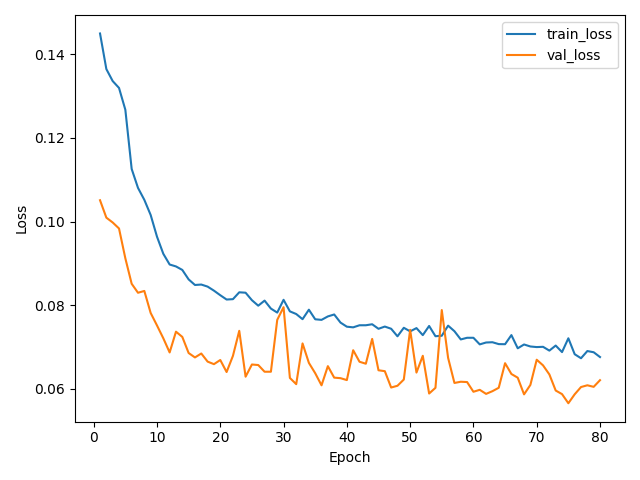

Selected epoch: 75
Completed epochs: 80


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
print('Selected epoch:', report['selected_epoch'])
print('Completed epochs:', len(report['history']))

## Held-out evaluation

MAE and RMSE are in degrees Celsius, averaged over all forecast hours and origins.

In [6]:
scores = pd.DataFrame(report['evaluation']).T
display(scores.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'log_rmse': 'Log-RMSE'}).round(4))

,MAE,RMSE
model,1.8077,2.3978
baseline_daily,2.5663,3.4088
baseline_persistence,2.8847,3.6364


## Forecasts through time

The four panels use January 15, April 15, July 15, and October 15, 2024—calendar dates chosen without ranking model error. The dashed divider separates known history from the 24-hour forecast. The red curve is the model forecast; black is the observed future; dotted blue repeats yesterday. All 731 held-out daily origins are included in the aggregate metrics.

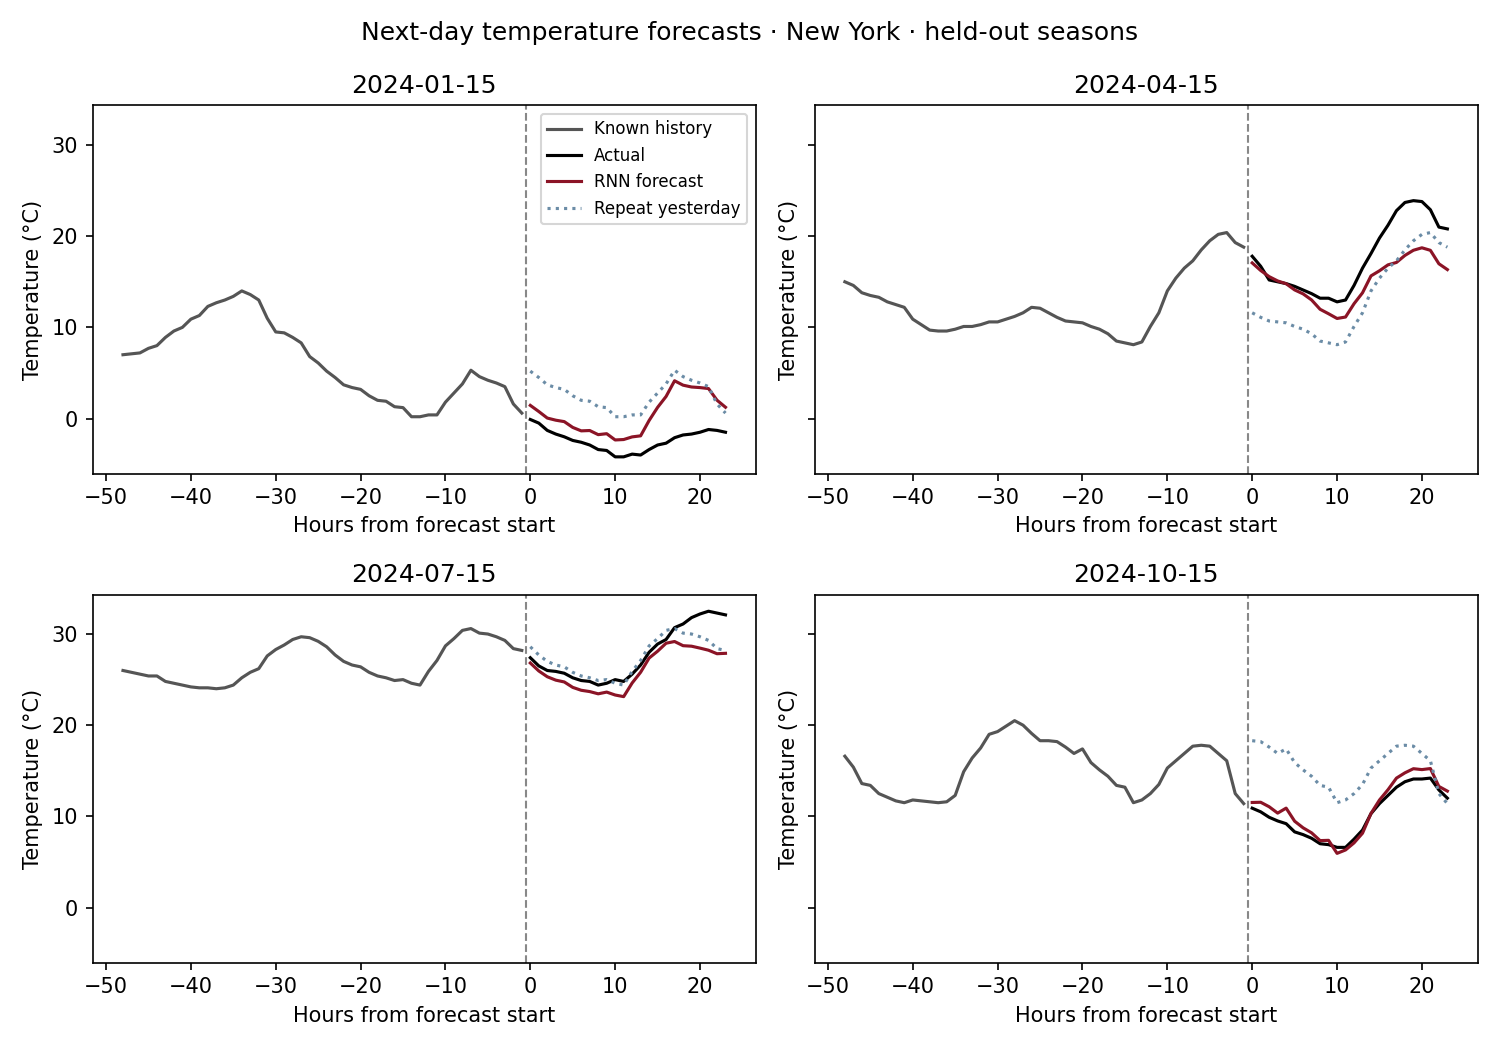

In [7]:
display(Image(filename=str(RUN / 'forecast.png')))

## Error by forecast horizon

Comparing error at each lead time shows how performance changes across the next day. The model has no future weather observations or numerical-weather forecast inputs.

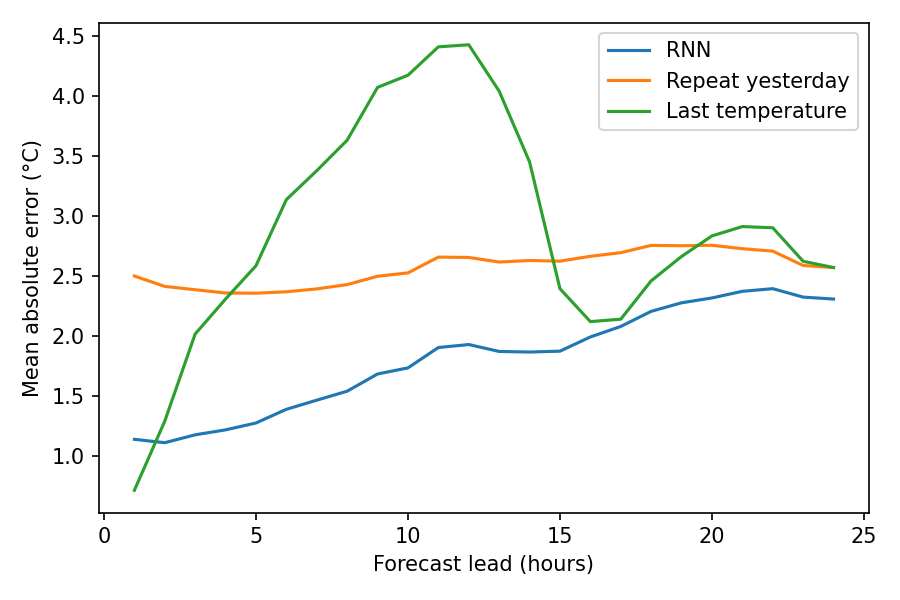

In [8]:
display(Image(filename=str(RUN / 'horizon_errors.png')))

## Restore the model and reproduce predictions

Load the selected checkpoint into the same architecture. The comparison below checks inference against the saved prediction records.

In [9]:
with np.load(RUN / 'predictions.npz', allow_pickle=False) as archive:
    records = {name: archive[name] for name in archive.files}
model = ForecastModel('rnn', hidden=report['config']['hidden'], rngs=nj.Rngs(params=0))
checkpoint.restore(RUN / 'best.npz', model=model)
model.eval()
replayed = decode(infer(model, records['inputs'][:64], batch_size=64), metadata)
np.testing.assert_allclose(replayed, records['predictions'][:64], rtol=1e-5, atol=1e-5)
print('Saved predictions reproduced from the checkpoint.')
display(pd.DataFrame({'Issued after': records['issued_at'][:5],
                      'Forecast begins': records['origins'][:5],
                      'Outcome available': records['outcome_available_at'][:5]}))

Saved predictions reproduced from the checkpoint.


,Issued after,Forecast begins,Outcome available
0,2023-12-31T23,2024-01-01T00,2024-01-01T23
1,2024-01-01T23,2024-01-02T00,2024-01-02T23
2,2024-01-02T23,2024-01-03T00,2024-01-03T23
3,2024-01-03T23,2024-01-04T00,2024-01-04T23
4,2024-01-04T23,2024-01-05T00,2024-01-05T23


## Visualization artifacts

`predictions.npz` retains every held-out forecast, baseline, target, input window, and timestamp. `visualization.json` describes the fields. `issued_at` marks the final known observation; `outcome_available_at` marks when the full target can be revealed. Temperature histories are in °C.

These records support a rolling square animation without retraining. Checkpoints, source data, and full prediction arrays remain local and gitignored. The notebook embeds the evaluated plots and metrics. This is a single-seed demonstration; improvements over these baselines do not establish performance across cities, market periods, or model configurations.